In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

In [3]:
from pathlib import Path

#Projectmap zoeken, werkt vanuit elke submap
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "prepared_data").exists())
OUTPUT_FILE = ROOT / "models" / "baseline" / "basic_impute_data_middenhuis.gzip"

df = pd.read_parquet(ROOT / "locatie_data" / "middenhuis479.parquet")

In [4]:
df['ENAME'].value_counts()

ENAME
hoofdmeter-5335bae8d497              397491
totaalverbruik-5335bae8d497          397491
overigverbruik-5335bae8d497          397461
drinkwaterpompen-5335bae8d497        370734
omvormer-5335bae8d497                364859
droger-5335bae8d497                  343214
wasmachine1-5335bae8d497             335969
helofytenfilterpomp-5335bae8d497     333852
priceele_c911efafaa                  171217
co2ele_c911efafaa                    165683
odectprice_c911efafaa                 95109
wasmachine2-5335bae8d497              83311
forec-totaalverbruik-5335bae8d497     17294
forec-omvormer-5335bae8d497           17294
priceele_123456                        1437
co2ele_92be2eca45                       677
Name: count, dtype: int64

In [5]:
totaalverbruik= df[df['ENAME']== 'totaalverbruik-5335bae8d497']
totaalverbruik.head(5)


,timestamp,CO2EQ,CTYPE,ENAME,EONNAME,ETYPE,GNAME,CO2,ENE,POW,...,COST_IMP,CTYPEC,ENE_CNT_EXP,ENE_CNT_IMP,ENE_EXP,ENE_IMP,ESTYPE,forecast.ENE,forecast.POW,PRICE
2676322,2024-03-08 01:00:00+01:00,NaN,electricity,totaalverbruik-5335bae8d497,eiot-5335bae8d497,powermeter,SERENE,NaN,NaN,115.225806,...,NaN,consumption,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN
2676323,2024-03-08 01:05:00+01:00,NaN,electricity,totaalverbruik-5335bae8d497,eiot-5335bae8d497,powermeter,SERENE,1.766796,9.602151,115.240000,...,NaN,consumption,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN
2676324,2024-03-08 01:10:00+01:00,NaN,electricity,totaalverbruik-5335bae8d497,eiot-5335bae8d497,powermeter,SERENE,1.767013,9.603333,115.140244,...,NaN,consumption,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN
2676325,2024-03-08 01:15:00+01:00,NaN,electricity,totaalverbruik-5335bae8d497,eiot-5335bae8d497,powermeter,SERENE,1.765484,9.595020,114.866667,...,NaN,consumption,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN
2676326,2024-03-08 01:20:00+01:00,NaN,electricity,totaalverbruik-5335bae8d497,eiot-5335bae8d497,powermeter,SERENE,1.761289,9.572222,115.363636,...,NaN,consumption,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN


C:\Users\stijn\AppData\Local\Temp\ipykernel_3552\802432170.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  totaalverbruik["timestamp"] = pd.to_datetime(totaalverbruik["timestamp"])


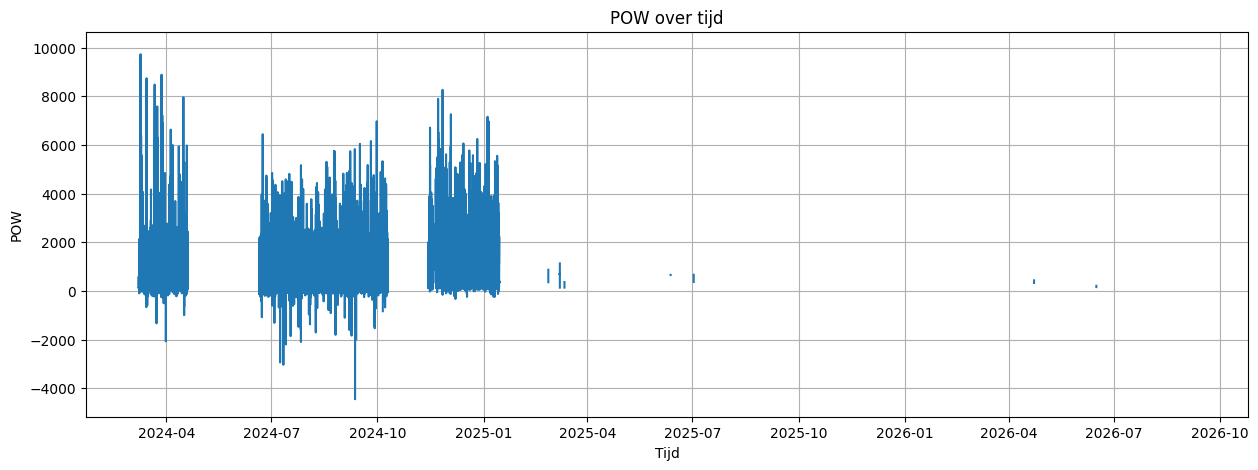

In [6]:
# Timestamp omzetten naar datetime
totaalverbruik["timestamp"] = pd.to_datetime(totaalverbruik["timestamp"])

# Sorteren op tijd
df_totaal = totaalverbruik.sort_values("timestamp")

# POW plotten tegenover tijd
plt.figure(figsize=(15, 5))
plt.plot(totaalverbruik["timestamp"], totaalverbruik["POW"])

plt.xlabel("Tijd")
plt.ylabel("POW")
plt.title("POW over tijd")
plt.grid()
plt.show()

In [7]:
df_driemaanden = totaalverbruik[
    (df_totaal['timestamp'] > '2024-07-01') &
    (df_totaal['timestamp'] < '2024-10-01')
]

C:\Users\stijn\AppData\Local\Temp\ipykernel_3552\1744410613.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_driemaanden = totaalverbruik[


C:\Users\stijn\AppData\Local\Temp\ipykernel_3552\456722636.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_driemaanden["timestamp"] = pd.to_datetime(df_driemaanden["timestamp"])


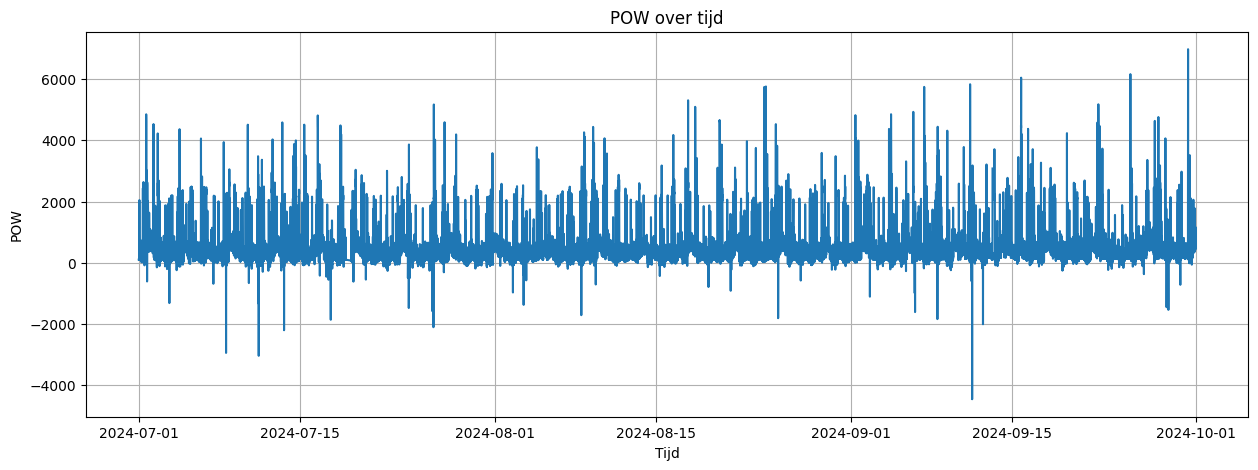

In [8]:
#  Timestamp omzetten naar datetime
df_driemaanden["timestamp"] = pd.to_datetime(df_driemaanden["timestamp"])



# POW plotten tegenover tijd
plt.figure(figsize=(15, 5))
plt.plot(df_driemaanden["timestamp"], df_driemaanden["POW"])

plt.xlabel("Tijd")
plt.ylabel("POW")
plt.title("POW over tijd")
plt.grid()
plt.show()

In [9]:
df_driemaanden.isnull().sum()

timestamp           0
CO2EQ           26267
CTYPE               0
ENAME               0
EONNAME             0
ETYPE               0
GNAME               0
CO2                20
ENE                 8
POW                 7
CO2_EXP         26267
CO2_IMP         26267
COST            26267
COST_EXP        26267
COST_IMP        26267
CTYPEC              0
ENE_CNT_EXP     26267
ENE_CNT_IMP     26267
ENE_EXP         26267
ENE_IMP         26267
ESTYPE          26267
forecast.ENE    26267
forecast.POW    26267
PRICE           26267
dtype: int64

In [10]:
df_driemaanden_impute= df_driemaanden.interpolate(method='linear')

C:\Users\stijn\AppData\Local\Temp\ipykernel_3552\3617871013.py:1: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df_driemaanden_impute= df_driemaanden.interpolate(method='linear')


In [11]:
df_driemaanden_impute['POW'].isnull().sum()

np.int64(0)

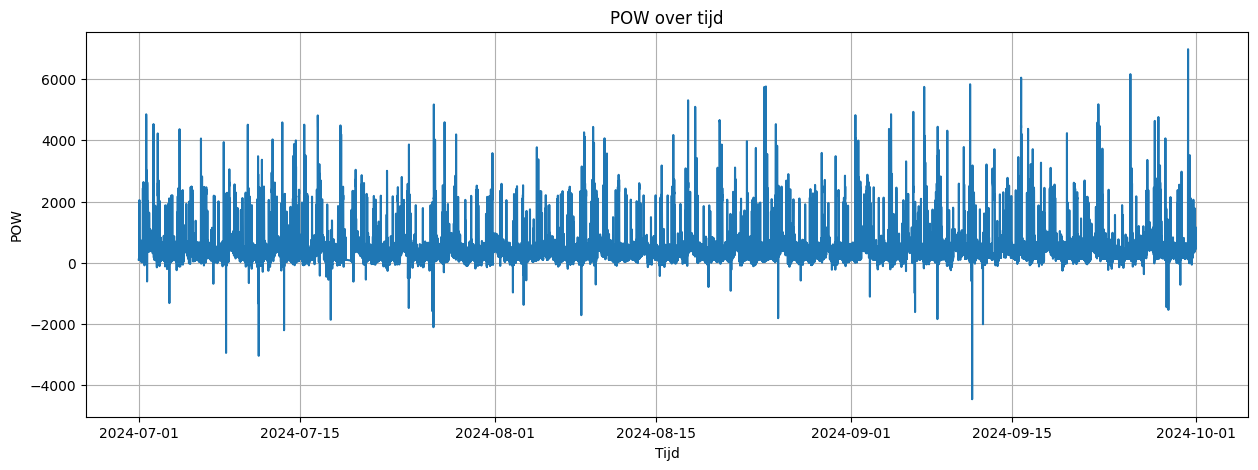

In [12]:
#  Timestamp omzetten naar datetime
df_driemaanden_impute["timestamp"] = pd.to_datetime(df_driemaanden_impute["timestamp"])

# POW plotten tegenover tijd
plt.figure(figsize=(15, 5))
plt.plot(df_driemaanden_impute["timestamp"], df_driemaanden_impute["POW"])

plt.xlabel("Tijd")
plt.ylabel("POW")
plt.title("POW over tijd")
plt.grid()
plt.show()

In [13]:
df_driemaanden_impute.to_parquet(OUTPUT_FILE)